In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("data/OIBSIP_Task3_Messy_Customer_Data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head(10)

,Customer_ID,Customer_Name,Gender,Age,City,Join_Date,Annual_Income,Spending_Score,Purchase_Amount
0,C001,Aarav Sharma,Male,24.0,Mumbai,2024-01-15,450000,72.0,1250.50
1,C002,Priya Patel,female,29.0,PUNE,15/02/2024,620000,85.0,2300.00
2,C003,Rohan Mehta,M,35.0,Navi Mumbai,Mar 03 2024,780000,60.0,1800.75
3,C004,Sneha Joshi,F,NaN,mumbai,2024/04/10,510000,90.0,950.00
4,C005,Kabir Khan,Male,41.0,Pune,2024-05-21,NaN,45.0,3100.00
5,C006,Isha Desai,Female,27.0,Thane,22-06-2024,560000,NaN,1450.25
6,C007,Dev Shah,male,31.0,NAVI MUMBAI,2024-07-09,690000,77.0,2100.00
7,C008,Meera Nair,F,22.0,Mumbai,08/08/2024,390000,88.0,800.00
8,C009,Arjun Rao,Male,150.0,Pune,2024-09-14,720000,55.0,1750.00
9,C010,Tara Kulkarni,Female,26.0,Thane,2024-10-02,0,92.0,1250.00


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      32 non-null     str    
 1   Customer_Name    32 non-null     str    
 2   Gender           32 non-null     str    
 3   Age              30 non-null     float64
 4   City             32 non-null     str    
 5   Join_Date        32 non-null     str    
 6   Annual_Income    31 non-null     str    
 7   Spending_Score   31 non-null     float64
 8   Purchase_Amount  31 non-null     float64
dtypes: float64(3), str(6)
memory usage: 2.4 KB


In [7]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Customer_ID        0
Customer_Name      0
Gender             0
Age                2
City               0
Join_Date          0
Annual_Income      1
Spending_Score     1
Purchase_Amount    1
dtype: int64


In [8]:
print("========== DATASET INFORMATION ==========")
df.info()

# Missing Values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

# Total Missing Values
print("\nTotal Missing Values:", df.isnull().sum().sum())

========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      32 non-null     str    
 1   Customer_Name    32 non-null     str    
 2   Gender           32 non-null     str    
 3   Age              30 non-null     float64
 4   City             32 non-null     str    
 5   Join_Date        32 non-null     str    
 6   Annual_Income    31 non-null     str    
 7   Spending_Score   31 non-null     float64
 8   Purchase_Amount  31 non-null     float64
dtypes: float64(3), str(6)
memory usage: 2.4 KB

========== MISSING VALUES ==========
Customer_ID        0
Customer_Name      0
Gender             0
Age                2
City               0
Join_Date          0
Annual_Income      1
Spending_Score     1
Purchase_Amount    1
dtype: int64

Total Missing Values: 5


In [9]:
# Check duplicate records
print("========== DUPLICATE RECORDS ==========")

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

========== DUPLICATE RECORDS ==========
Total Duplicate Rows: 0


In [10]:
df[df.duplicated(keep=False)]

,Customer_ID,Customer_Name,Gender,Age,City,Join_Date,Annual_Income,Spending_Score,Purchase_Amount


In [11]:
# Check duplicate customer details, ignoring Customer_ID

duplicates = df[df.duplicated(
    subset=["Customer_Name", "Gender", "Age", "City",
            "Join_Date", "Annual_Income", "Spending_Score",
            "Purchase_Amount"],
    keep=False
)]

print("Repeated Customer Records:")
display(duplicates)

Repeated Customer Records:


,Customer_ID,Customer_Name,Gender,Age,City,Join_Date,Annual_Income,Spending_Score,Purchase_Amount
0,C001,Aarav Sharma,Male,24.0,Mumbai,2024-01-15,450000,72.0,1250.5
24,C025,Aarav Sharma,Male,24.0,Mumbai,2024-01-15,450000,72.0,1250.5
25,C026,Aarav Sharma,Male,24.0,Mumbai,2024-01-15,450000,72.0,1250.5


In [12]:
print("Total repeated customer records:", len(duplicates))

Total repeated customer records: 3


In [13]:
# Remove repeated customer records while ignoring Customer_ID

before = len(df)

df = df.drop_duplicates(
    subset=["Customer_Name", "Gender", "Age", "City",
            "Join_Date", "Annual_Income", "Spending_Score",
            "Purchase_Amount"],
    keep="first"
)

after = len(df)

print("Records before cleaning:", before)
print("Records after cleaning:", after)
print("Duplicate records removed:", before - after)

Records before cleaning: 32
Records after cleaning: 30
Duplicate records removed: 2


In [14]:
print("Remaining duplicate customer records:",
      df.duplicated(
          subset=["Customer_Name", "Gender", "Age", "City",
                  "Join_Date", "Annual_Income", "Spending_Score",
                  "Purchase_Amount"]
      ).sum())

Remaining duplicate customer records: 0


In [15]:
# Standardise Gender
df["Gender"] = df["Gender"].str.strip().str.lower()

df["Gender"] = df["Gender"].replace({
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female"
})

# Standardise City
df["City"] = df["City"].str.strip().str.title()

# Display cleaned values
print("Gender Values:")
print(df["Gender"].unique())

print("\nCity Values:")
print(df["City"].unique())

Gender Values:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

City Values:
<StringArray>
['Mumbai', 'Pune', 'Navi Mumbai', 'Thane']
Length: 4, dtype: str


In [16]:
# Convert different date formats into standard datetime format

df["Join_Date"] = pd.to_datetime(
    df["Join_Date"],
    format="mixed",
    errors="coerce",
    dayfirst=True
)

# Display date column
print("Date conversion completed!")
display(df[["Customer_Name", "Join_Date"]].head(15))

# Count invalid dates
print("Invalid or missing dates:",
      df["Join_Date"].isnull().sum())

Date conversion completed!


,Customer_Name,Join_Date
0,Aarav Sharma,2024-01-15
1,Priya Patel,2024-02-15
2,Rohan Mehta,2024-03-03
3,Sneha Joshi,2024-10-04
4,Kabir Khan,2024-05-21
5,Isha Desai,2024-06-22
6,Dev Shah,2024-09-07
7,Meera Nair,2024-08-08
8,Arjun Rao,2024-09-14
9,Tara Kulkarni,2024-02-10


Invalid or missing dates: 2


In [17]:
# Convert columns into numeric data types

numeric_columns = [
    "Age",
    "Annual_Income",
    "Spending_Score",
    "Purchase_Amount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Correct invalid values
df.loc[~df["Age"].between(0, 100), "Age"] = np.nan

df.loc[df["Annual_Income"] <= 0, "Annual_Income"] = np.nan

df.loc[~df["Spending_Score"].between(0, 100), "Spending_Score"] = np.nan

df.loc[df["Purchase_Amount"] < 0, "Purchase_Amount"] = np.nan

print("Numerical data cleaning completed!")

print("\nMissing values after correction:")
print(df.isnull().sum())

Numerical data cleaning completed!

Missing values after correction:
Customer_ID        0
Customer_Name      0
Gender             0
Age                4
City               0
Join_Date          2
Annual_Income      3
Spending_Score     2
Purchase_Amount    2
dtype: int64


In [18]:
# Fill missing numerical values using median

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing numerical values filled successfully!")

print("\nMissing values after filling:")
print(df.isnull().sum())

Missing numerical values filled successfully!

Missing values after filling:
Customer_ID        0
Customer_Name      0
Gender             0
Age                0
City               0
Join_Date          2
Annual_Income      0
Spending_Score     0
Purchase_Amount    0
dtype: int64


In [19]:
# Detect outliers using the IQR method

outlier_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append([
        col, lower, upper, count
    ])

outlier_summary_df = pd.DataFrame(
    outlier_summary,
    columns=["Column", "Lower_Bound", "Upper_Bound", "Outlier_Count"]
)

display(outlier_summary_df)

,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Age,16.875,43.875,1
1,Annual_Income,290000.000,970000.000,0
2,Spending_Score,29.500,117.500,0
3,Purchase_Amount,31.250,3521.250,3


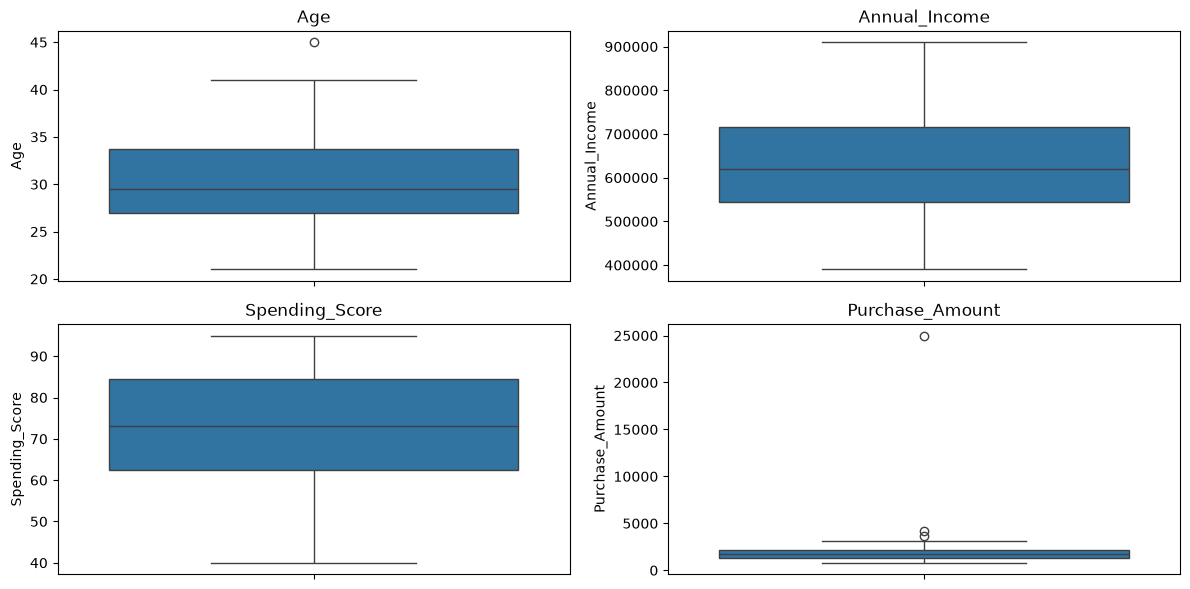

In [20]:
# Visualise outliers using boxplots

plt.figure(figsize=(12, 6))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [23]:
# Save the cleaned dataset

df.to_csv("data/OIBSIP_Task3_Messy_Customer_Data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [26]:
# Save outlier report

outlier_summary_df.to_csv(
    "output/outlier_summary.csv",
    index=False
)

print("Outlier report saved successfully!")

Outlier report saved successfully!


In [29]:
# Create Data Quality Report

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values
})

quality_report.to_csv(
    "output/data_quality_report.csv",
    index=False
)

display(quality_report)

print("Data Quality Report saved successfully!")

,Column,Data_Type,Missing_Values
0,Customer_ID,str,0
1,Customer_Name,str,0
2,Gender,str,0
3,Age,float64,0
4,City,str,0
5,Join_Date,datetime64[us],2
6,Annual_Income,float64,0
7,Spending_Score,float64,0
8,Purchase_Amount,float64,0


Data Quality Report saved successfully!


In [30]:
# Save cleaned dataset again

import os

os.makedirs("outputs", exist_ok=True)

df.to_csv(
    "outputs/cleaned_customer_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("File location:", os.path.abspath("outputs/cleaned_customer_data.csv"))

Cleaned dataset saved successfully!
File location: c:\Users\Sumit\Downloads\DataAnalytics-L1-CleaningData\outputs\cleaned_customer_data.csv
